In [18]:
# Loading libraries

import os
import numpy as np
import pandas as pd
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.table import Table, QTable
from matplotlib import pyplot as plt
from multiprocessing import Pool, cpu_count
from tqdm.notebook import tqdm
# vstack is used to concatenate tables
from astropy.table import vstack


In [2]:
#catalog = 'glimpse2_v2cat'
catalog = 'glimpse_s07'

In [3]:
alma_regions = Table.read("../alma_input/almaprops_2024_all_20250219.tab", format="ascii.ipac")
print(alma_regions[:2])
print("\n\n\n")

    ALMAGAL_ID           ORIG_ID        INTERNAL_ID ... FIT_FLAG OBS_SAMPLE
                                                    ...                    
----------------- --------------------- ----------- ... -------- ----------
AG010.1313-0.7687 HIGALBM10.1330-0.7710       46677 ...        -       near
AG010.1392-0.7831 HIGALBM10.1395-0.7833       46696 ...        -       near






In [4]:
spitzer_sources = Table.read("../output/tables/spitzer_sources_"+catalog+".tbl", format="ascii.ipac")
print(spitzer_sources[:2])
print("\n\n\n")

cntr_01  dist_x    pang_x   internal_id_01 ... color45_58 color45_80 color58_80
         arcsec     deg                    ...                                 
------- -------- ---------- -------------- ... ---------- ---------- ----------
      1 2.867081 -55.508188          46677 ...      0.471      0.367     -0.104
      1 4.406157  86.064855          46677 ...         --         --         --






In [5]:
alma_sources = pd.read_csv('../alma_input/7MTM2TM1_Core_catalogue_out_official_v3_run6Apr23+16Jan24_sn-5_may24_clump_cat.txt', comment='\\', skiprows=[2], delimiter='\s+')
print(alma_sources[6001:6004])
print("\n\n\n")

      ID               CLUMP          X          Y         RA        DEC  \
6001  22  G323.7399-00.2617B  386.92831  335.97809  232.93886 -56.514006   
6002  23  G323.7399-00.2617B  374.90641  340.99945  232.93932 -56.513900   
6003  20  G323.7399-00.2617B  355.04385  326.97879  232.94008 -56.514196   

           GLON      GLAT     F_PEAK         S/N  ...  Back_onpeak_jybm  \
6001  323.73984 -0.262544  1489.3764   31.570764  ...          0.004688   
6002  323.74011 -0.262602  6066.5668  128.594859  ...          0.006919   
6003  323.74028 -0.263085  1283.1450   27.199214  ...          0.011580   

            Rcore  Surfd_core        n(H2)              AG_ID  \
6001   984.988790    3.902623   63200000.0  AG323.7408-0.2633   
6002  1044.259595   15.896265  243000000.0  AG323.7408-0.2633   
6003   973.958180    3.362233   55100000.0  AG323.7408-0.2633   

                 ORIG_ID  RADIO_INFO  RADIO_MATCH  Surfd_nd VLSR_clump  
6001  G323.7399-00.2617B           1            0      1.58 

In [6]:
def source_match(region):

    match_table_local = QTable(
    names=['region_id','alma_source','spitzer_source','alma_ra','alma_dec','spitzer_ra','spitzer_dec','separation_arcsec'],
    units=[None, None, None, 'deg', 'deg', 'deg', 'deg', 'arcsec deg'],
    dtype=['str','int64','str','float64','float64','float64','float64','float64']
    )

    spitzer_sources_cut = spitzer_sources[spitzer_sources["internal_id_01"] == str(region["INTERNAL_ID"])]
    alma_sources_cut = alma_sources[alma_sources["CLUMP"] == str(region["INTERNAL_ID"])].reset_index(drop=True)

    for alma_index in range(len(alma_sources_cut)):
        
        source_coords = SkyCoord(alma_sources_cut["RA"][alma_index], alma_sources_cut["DEC"][alma_index], unit=(u.deg, u.deg), frame="icrs")
        radius = 0.6*u.arcsec+0.25*u.arcsec # Spitzer resolution + ALMA resolution (assuming 0.25" for ALMA)
        spitzer_coords = SkyCoord(spitzer_sources_cut["ra"], spitzer_sources_cut["dec"], unit=(u.deg, u.deg), frame="icrs")
        seps = source_coords.separation(spitzer_coords)

        for spitzer_index in range(len(spitzer_sources_cut)):

            # Only consider the spitzer source with the minimum separation to the alma source

            if seps[spitzer_index] < radius and seps[spitzer_index] == np.min(seps):
                match_table_local.add_row([alma_sources_cut["CLUMP"][alma_index], (alma_index+1), spitzer_sources_cut["designation"][spitzer_index], 
                                     source_coords.ra.deg*u.deg, source_coords.dec.deg*u.deg,spitzer_sources_cut["ra"][spitzer_index]*u.deg, spitzer_sources_cut["dec"][spitzer_index]*u.deg,(seps[spitzer_index]*3600)*u.arcsec])
    return match_table_local


In [7]:
match_table = QTable(
    names=['region_id','alma_source','spitzer_source','alma_ra','alma_dec','spitzer_ra','spitzer_dec','separation_arcsec'],
    units=[None, None, None, 'deg', 'deg', 'deg', 'deg', 'arcsec deg'],
    dtype=['str','int64','str','float64','float64','float64','float64','float64']
)


test_regions = len(alma_regions) # Set this to a smaller number for testing, e.g., 10 or 20
#test_regions = 100
regions_subset = alma_regions[:test_regions]


if os.name == 'nt':  # For Windows
    print("Running on Windows. Parallel work is not supported. Processing regions sequentially...")
    for region in tqdm(regions_subset, total=len(regions_subset)):
        result = source_match(region)
        match_table = vstack([match_table, result])
else:
    with Pool(cpu_count()) as pool:
        print(cpu_count(), "cores available. Processing regions in parallel...")
        results = tqdm(pool.map(source_match, regions_subset), total=len(regions_subset))
        #results = pool.map(source_match, regions_subset)
        
    for result in results:
        match_table = vstack([match_table, result])

print('done!')


Running on Windows. Parallel work is not supported. Processing regions sequentially...


  0%|          | 0/1017 [00:00<?, ?it/s]

done!


In [ ]:
match_table['separation_arcsec'].format = "{:.2E}"

print(match_table)

match_table.write("../output/tables/match_table_"+catalog+".tbl", format="ascii.ipac", overwrite=True)
match_table = Table.read('../output/tables/match_table_'+catalog+'.tbl',format='ipac')

    region_id     alma_source ... spitzer_dec  separation_arcsec 
                              ...     deg          arcsec deg    
----------------- ----------- ... ----------- -------------------
            47184           2 ...  -20.191348  0.6168242796454642
            49005           3 ...  -19.811121  0.2851707572111167
G010.8856+00.1221           2 ...  -19.456672   0.372521157186798
            50555           6 ...  -19.597059  0.4282517597218486
            51554           4 ...  -18.709532 0.24499245088841778
            51554           5 ...  -18.708429 0.49630287338405427
            52831           1 ...  -18.949053  0.7828677778564165
            53795           1 ...  -18.694229  0.7414087104302064
            53795           9 ...  -18.691359 0.28294803023908505
              ...         ... ...         ...                 ...
           876288          22 ...  -39.158065  0.4460129709053723
           877689           1 ...  -38.831309 0.48251643891930873
          

---

In [9]:
def plot_separation_histogram(match_table,bins):
    plt.figure(figsize=(8, 6))
    plt.hist(match_table['separation_arcsec'], bins=bins, color='skyblue', edgecolor='black')
    plt.title('Distribution of Separations Between ALMA and Spitzer Sources')
    plt.xlabel('Separation (arcseconds)')
    plt.ylabel('Number of Matches')
    plt.axvline(0.85, color='black', linestyle='--', label='Matching Radius (0.85 arcsec)')
    plt.axvline(0.25, color='red', linestyle='-', label='ALMA Resolution (0.25 arcsec)')
    plt.legend()
    plt.grid(axis='y', alpha=0.75)
    plt.show()

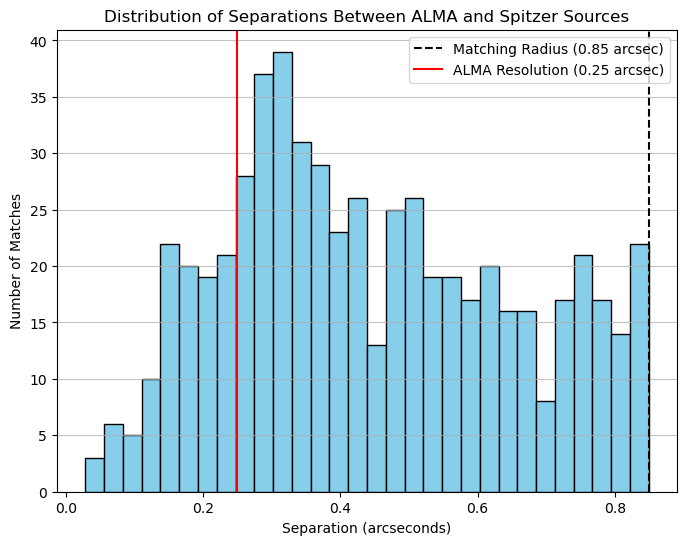

In [10]:
plot_separation_histogram(match_table,30)

In [11]:
def plot_source_matches(match_table,region_id):
    
    region_matches = match_table[match_table['region_id'] == region_id]
    
    for alma_source in set(region_matches['alma_source']):
        #plt.figure(figsize=(5, 5))
        _, ax = plt.subplots()

        alma_source_matches = region_matches[region_matches['alma_source'] == alma_source]
        radius = 0.6*u.arcsec+0.25*u.arcsec # Spitzer resolution + ALMA resolution (assuming 0.25" for ALMA)
        ax.scatter([0], [0], color="red", label="ALMA Source",alpha=1)
        ax.scatter((alma_source_matches['spitzer_ra']-alma_source_matches['alma_ra'])*np.cos(np.deg2rad(alma_source_matches['alma_dec']))*3600, (alma_source_matches['spitzer_dec']-alma_source_matches['alma_dec'])*3600, color="blue", label="Spitzer Source",alpha=0.5)
        circle_total = plt.Circle((0, 0), radius.to_value(u.arcsec), color='black', fill=False, linestyle='--', label='Matching Radius (0.85 arcsec)')
        ax.add_patch(circle_total)

        ax.set_title(f"Source {alma_source} in Region {region_id}")


        ax.set_ylim(-1, 1)
        ax.set_xlim(-1, 1)
        ax.set_ylabel("Declination (arcsec)")
        ax.set_xlabel("Right Ascension (arcsec)") 
        ax.set_aspect('equal', adjustable='box')

    plt.show()

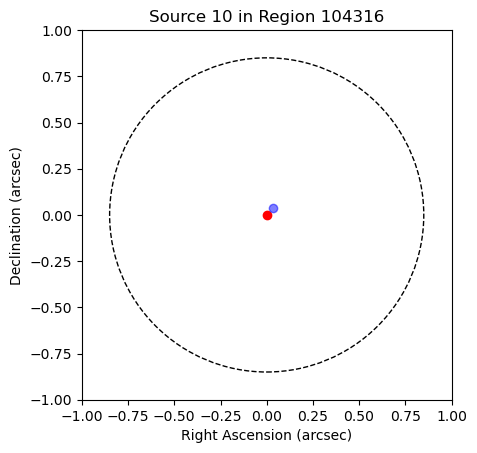

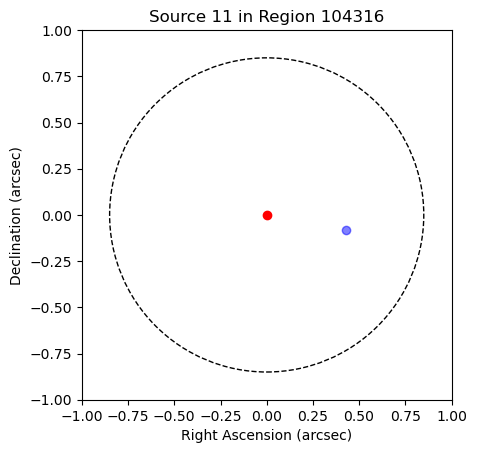

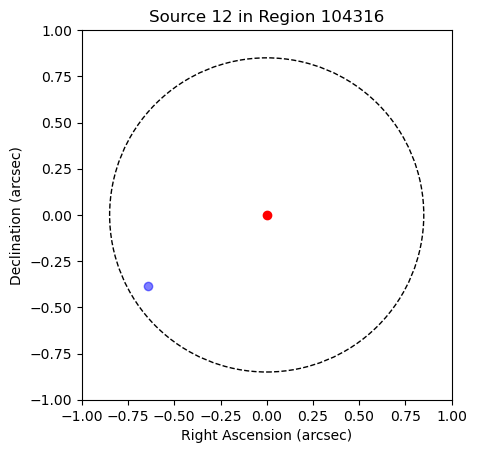

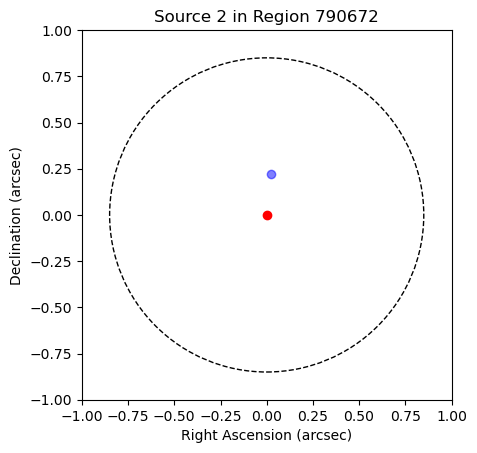

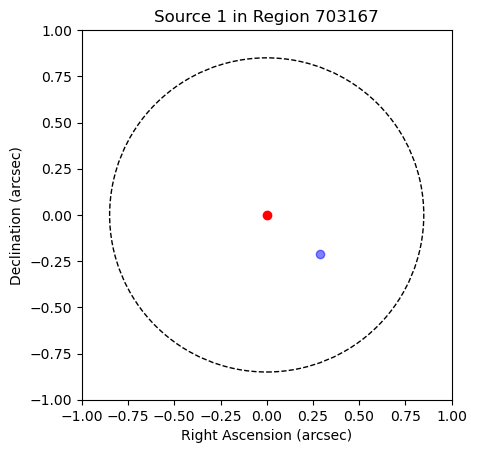

In [12]:
test_sources = len(match_table) # Set this to a smaller number for testing, e.g., 10 or 20
test_sources = 3

for region_id in list(set(match_table['region_id']))[:test_sources]:
    plot_source_matches(match_table, region_id)



In [15]:
def plot_source_matches_all(match_table,region_id,ax):
    region_matches = match_table[match_table['region_id'] == region_id]

    for alma_source in set(region_matches['alma_source']):
        alma_source_matches = region_matches[region_matches['alma_source'] == alma_source]
        ax.scatter((alma_source_matches['spitzer_ra']-alma_source_matches['alma_ra'])*np.cos(np.deg2rad(alma_source_matches['alma_dec']))*3600, (alma_source_matches['spitzer_dec']-alma_source_matches['alma_dec'])*3600, color="blue",alpha=0.5)     

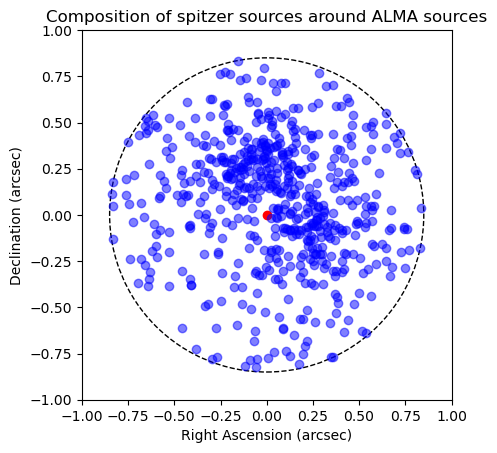

589


In [19]:
test_sources = len(match_table) # Set this to a smaller number for testing, e.g., 10 or 20
#test_sources = 10

_, ax = plt.subplots()

ax.scatter([0], [0], color="red", label="ALMA Source",alpha=1)

radius = 0.6*u.arcsec+0.25*u.arcsec # Spitzer resolution + ALMA resolution (assuming 0.25" for ALMA)

circle_total = plt.Circle((0, 0), radius.to_value(u.arcsec), color='black', fill=False, linestyle='--', label='Matching Radius (0.85 arcsec)')
ax.add_patch(circle_total)
ax.set_ylim(-1, 1)
ax.set_xlim(-1, 1)
ax.set_ylabel("Declination (arcsec)")
ax.set_xlabel("Right Ascension (arcsec)") 
ax.set_aspect('equal', adjustable='box')
ax.set_title("Composition of spitzer sources around ALMA sources")

for region_id in list(set(match_table['region_id']))[:test_sources]:
    plot_source_matches_all(match_table, region_id,ax)

os.makedirs('../output/figures',exist_ok=True)

plt.savefig('../output/figures/match_'+catalog+'_plot.svg',format='svg')
plt.show()

print(len(match_table))


In [23]:
x = []
y = []
for match in match_table:
    x.append(((match['spitzer_ra'] - match['alma_ra'])*3600*np.cos(np.deg2rad(match['alma_dec']))).value)
    y.append(((match['spitzer_dec'] - match['alma_dec'])*3600).value)
print(x)
print(y)

[np.float64(-0.5777681744469372), np.float64(0.2540201082038202), np.float64(0.36320268619296336), np.float64(-0.05426354085382099), np.float64(-0.22163468269738484), np.float64(0.4944191738452896), np.float64(-0.05107368198817461), np.float64(0.5660717129556821), np.float64(0.2796307248412809), np.float64(-0.04427559724631174), np.float64(0.48702841015954523), np.float64(0.24524010819366404), np.float64(0.4782178003035425), np.float64(0.39622328040933685), np.float64(0.40694893840055985), np.float64(0.21908661897807183), np.float64(0.1096263509676036), np.float64(0.03089614576840889), np.float64(0.5458325597336001), np.float64(0.13731822585000733), np.float64(-0.15418920201784891), np.float64(-0.6338900721314586), np.float64(-0.02057049709863308), np.float64(0.538263440368635), np.float64(0.02399901568919327), np.float64(0.16123881847547164), np.float64(-0.3190472505282092), np.float64(0.2197690544214575), np.float64(0.23340286153380374), np.float64(-0.15789066785096448), np.float64(0

In [21]:
def ring(radius,color,linewidth):
    theta = np.linspace(0,2*np.pi,500)
    x_r = radius * np.cos(theta)
    y_r = radius * np.sin(theta)
    plt.plot(x_r,y_r,color = color,linewidth=linewidth,linestyle='--')
    return 0

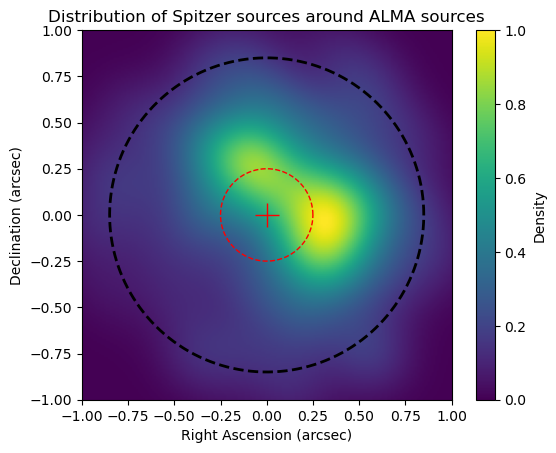

In [22]:
from scipy.stats import gaussian_kde

xy = np.vstack([x, y])
kde = gaussian_kde(xy)

# grid
xi, yi = np.mgrid[min(x):max(x):200j, min(y):max(y):200j]
zi = kde(np.vstack([xi.flatten(), yi.flatten()]))

plt.imshow(zi.reshape(xi.shape),
           origin='lower',
           extent=[-1, 1, -1, 1],
           cmap='viridis')

ring(radius,'black',2)
ring(0.25,'red',1)
plt.scatter(0,0,color='red',linewidth=1,s=300,marker='+')

plt.colorbar(label='Density')
plt.gca().set_aspect('equal')
plt.ylabel('Declination (arcsec)')
plt.xlabel('Right Ascension (arcsec)')
plt.title('Distribution of Spitzer sources around ALMA sources')
plt.savefig('../output/figures/match_'+catalog+'_heatmap.svg',format='svg')
plt.show()